<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/08_HMM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Modelos ocultos de Markov</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">Cadenas de Markov</span>](#cadenas-de-markov)
- [<span style="color: #005C99;">Modelos ocultos de Markov</span>](#modelos-ocultos-de-markov)
- [<span style="color: #005C99;">Los tres problemas fundamentales</span>](#los-tres-problemas-fundamentales)
- [<span style="color: #005C99;">Verosimilitud: el algoritmo forward</span>](#verosimilitud-el-algoritmo-forward)
- [<span style="color: #005C99;">Aprendizaje supervisado: un HMM para etiquetado gramatical</span>](#aprendizaje-supervisado-un-hmm-para-etiquetado-gramatical)
- [<span style="color: #005C99;">El HMM como modelo generativo</span>](#el-hmm-como-modelo-generativo)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib seaborn nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import itertools
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import cess_esp

SEED = 42
np.random.seed(SEED)

_ = nltk.download("cess_esp", quiet=True)

<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

Hasta ahora clasificamos unidades aisladas: un tweet, una reseña, un nombre. Pero muchas tareas de PLN asignan una etiqueta **a cada elemento de una secuencia**, y las etiquetas vecinas dependen unas de otras:

| Tarea | Secuencia de entrada | Secuencia de salida |
|-------|----------------------|---------------------|
| Etiquetado gramatical | *la vieja cierra la puerta* | `DET NOUN VERB DET NOUN` |
| Reconocimiento de entidades | *García Márquez nació en Aracataca* | `B-PER I-PER O O B-LOC` |
| Reconocimiento de voz | Señal de audio por ventanas | Fonemas |

En el cuaderno 02 vimos que etiquetar cada palabra por separado con su etiqueta más frecuente llega a ≈92 %, y que el salto a ≈97 % viene de **usar el contexto**. Los **modelos ocultos de Markov** (HMM, *Hidden Markov Models*) fueron durante décadas la herramienta estándar para hacerlo de forma probabilística. Este cuaderno presenta el modelo y cómo estimarlo; el siguiente, cómo usarlo para etiquetar (algoritmo de Viterbi).

<a id="cadenas-de-markov"></a>
<h2 style="color: #007ACC;">Cadenas de Markov</h2>

Una **cadena de Markov** es un proceso que pasa por una secuencia de **estados** $q_1, q_2, \dots$ donde el siguiente estado solo depende del actual (**propiedad de Markov**):

$$P(q_t \mid q_1, \dots, q_{t-1}) = P(q_t \mid q_{t-1})$$

Se describe con:

- Un conjunto de $N$ estados.
- Una **distribución inicial** $\pi_i = P(q_1 = i)$.
- Una **matriz de transición** $A$ con $a_{ij} = P(q_t = j \mid q_{t-1} = i)$. Cada fila suma 1.

Es exactamente el supuesto de los modelos de bigramas del cuaderno 06, donde los estados eran palabras. Un ejemplo con el clima:

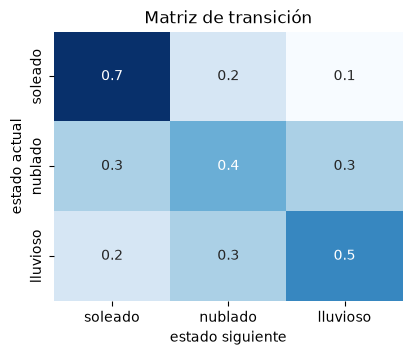

In [3]:
estados_clima = ["soleado", "nublado", "lluvioso"]
pi_clima = np.array([0.5, 0.3, 0.2])
A_clima = np.array([
    [0.7, 0.2, 0.1],   # desde soleado
    [0.3, 0.4, 0.3],   # desde nublado
    [0.2, 0.3, 0.5],   # desde lluvioso
])
assert np.allclose(A_clima.sum(axis=1), 1)

plt.figure(figsize=(4.5, 3.5))
sns.heatmap(A_clima, annot=True, cmap="Blues", xticklabels=estados_clima, yticklabels=estados_clima, cbar=False)
plt.xlabel("estado siguiente")
plt.ylabel("estado actual")
plt.title("Matriz de transición")
plt.show()

La probabilidad de una secuencia de estados es el producto de la probabilidad inicial y las transiciones:

$$P(q_1, \dots, q_T) = \pi_{q_1} \prod_{t=2}^{T} a_{q_{t-1} q_t}$$

In [4]:
def prob_secuencia(secuencia, pi, A, estados):
    idx = [estados.index(s) for s in secuencia]
    p = pi[idx[0]]
    for i, j in zip(idx, idx[1:]):
        p *= A[i, j]
    return p


for sec in [["soleado"] * 4, ["soleado", "lluvioso", "soleado", "lluvioso"]]:
    print(f"P({', '.join(sec)}) = {prob_secuencia(sec, pi_clima, A_clima, estados_clima):.4f}")

P(soleado, soleado, soleado, soleado) = 0.1715
P(soleado, lluvioso, soleado, lluvioso) = 0.0010


Si dejamos correr la cadena mucho tiempo, la proporción de días en cada estado converge a la **distribución estacionaria** $\boldsymbol{\mu}$, que cumple $\boldsymbol{\mu} A = \boldsymbol{\mu}$. Podemos encontrarla simulando o multiplicando repetidamente por $A$:

In [5]:
rng = np.random.default_rng(SEED)
estado = rng.choice(3, p=pi_clima)
visitas = np.zeros(3)
for _ in range(100_000):
    visitas[estado] += 1
    estado = rng.choice(3, p=A_clima[estado])

mu = np.linalg.matrix_power(A_clima, 50)[0]  # cualquier fila de A^n converge a mu
pd.DataFrame({"simulación": visitas / visitas.sum(), "A^50": mu}, index=estados_clima).round(3)

,simulación,A^50
soleado,0.456,0.457
nublado,0.282,0.283
lluvioso,0.262,0.261


<a id="modelos-ocultos-de-markov"></a>
<h2 style="color: #007ACC;">Modelos ocultos de Markov</h2>

En muchos problemas **no observamos los estados** directamente, sino algo que depende de ellos. En el etiquetado gramatical observamos las **palabras**, pero las **etiquetas** (los estados) están ocultas.

Un **HMM** añade a la cadena de Markov:

- Un conjunto de **observaciones** posibles (el vocabulario).
- Una **matriz de emisión** $B$ con $b_j(o) = P(o_t = o \mid q_t = j)$: la probabilidad de que el estado $j$ "emita" la observación $o$.

Y hace dos supuestos:

1. **Markov:** el estado actual solo depende del anterior, $P(q_t \mid q_{t-1})$.
2. **Independencia de las observaciones:** cada observación solo depende del estado que la emite, $P(o_t \mid q_t)$.

```text
estados ocultos:   q1 ──a──▶ q2 ──a──▶ q3 ──a──▶ ...
                   │         │         │
                   b         b         b
                   ▼         ▼         ▼
observaciones:     o1        o2        o3
```

La probabilidad conjunta de una secuencia de estados y observaciones es:

$$P(O, Q) = \pi_{q_1}\, b_{q_1}(o_1) \prod_{t=2}^{T} a_{q_{t-1} q_t}\, b_{q_t}(o_t)$$

**Ejemplo clásico (Eisner, 2002):** queremos reconstruir el clima de un verano pasado (caluroso **C** o frío **F**) a partir del diario de una persona que anotó cuántos helados comió cada día (1, 2 o 3). El clima está oculto; los helados son las observaciones.

In [6]:
estados = ["C", "F"]          # caluroso, frío
observaciones = [1, 2, 3]     # helados comidos
pi = np.array([0.8, 0.2])
A = np.array([[0.6, 0.4],     # C -> C, C -> F
              [0.5, 0.5]])    # F -> C, F -> F
B = np.array([[0.2, 0.4, 0.4],   # P(1|C), P(2|C), P(3|C)
              [0.5, 0.4, 0.1]])  # P(1|F), P(2|F), P(3|F)

pd.concat([
    pd.DataFrame(A, index=estados, columns=[f"→{e}" for e in estados]),
    pd.DataFrame(B, index=estados, columns=[f"{o} helado(s)" for o in observaciones]),
], axis=1, keys=["transición A", "emisión B"])

transición A        emisión B                        
            →C   →F 1 helado(s) 2 helado(s) 3 helado(s)
C          0.6  0.4         0.2         0.4         0.4
F          0.5  0.5         0.5         0.4         0.1

Un HMM es un **modelo generativo**: describe cómo se producen los datos. Podemos muestrear secuencias de él:

In [7]:
def muestrear_hmm(pi, A, B, T, rng):
    q = rng.choice(len(pi), p=pi)
    estados_gen, obs_gen = [], []
    for _ in range(T):
        estados_gen.append(q)
        obs_gen.append(rng.choice(B.shape[1], p=B[q]))
        q = rng.choice(len(pi), p=A[q])
    return estados_gen, obs_gen


rng = np.random.default_rng(SEED)
q_gen, o_gen = muestrear_hmm(pi, A, B, 10, rng)
print("clima (oculto):", " ".join(estados[q] for q in q_gen))
print("helados:       ", " ".join(str(observaciones[o]) for o in o_gen))

clima (oculto): C F C F C C F C C F
helados:        2 2 3 2 2 3 2 2 1 2


<a id="los-tres-problemas-fundamentales"></a>
<h2 style="color: #007ACC;">Los tres problemas fundamentales</h2>

Rabiner (1989) formuló los tres problemas que hay que saber resolver con un HMM:

| Problema | Pregunta | Algoritmo | Dónde |
|----------|----------|-----------|-------|
| **1. Verosimilitud** | Dado el modelo $\lambda = (\pi, A, B)$ y una secuencia $O$, ¿cuánto vale $P(O \mid \lambda)$? | Forward | Este cuaderno |
| **2. Decodificación** | Dado $\lambda$ y $O$, ¿cuál es la secuencia de estados $Q$ más probable? | Viterbi | Cuaderno 09 |
| **3. Aprendizaje** | Dadas observaciones (y quizá estados), ¿cuáles son los mejores $\pi, A, B$? | Conteo (supervisado) o Baum-Welch (no supervisado) | Este cuaderno |

<a id="verosimilitud-el-algoritmo-forward"></a>
<h2 style="color: #007ACC;">Verosimilitud: el algoritmo forward</h2>

Queremos $P(O)$ para una secuencia de observaciones, por ejemplo *3 1 3* helados. Como no conocemos los estados, hay que **sumar sobre todas las secuencias de estados posibles**:

$$P(O) = \sum_{Q} P(O, Q)$$

Con $N$ estados y $T$ observaciones hay $N^T$ secuencias. Por fuerza bruta:

In [8]:
def prob_conjunta(obs, q, pi, A, B):
    p = pi[q[0]] * B[q[0], obs[0]]
    for t in range(1, len(obs)):
        p *= A[q[t - 1], q[t]] * B[q[t], obs[t]]
    return p


def verosimilitud_fuerza_bruta(obs, pi, A, B):
    return sum(prob_conjunta(obs, q, pi, A, B) for q in itertools.product(range(len(pi)), repeat=len(obs)))


obs = [observaciones.index(o) for o in [3, 1, 3]]
for q in itertools.product(range(2), repeat=3):
    print("".join(estados[i] for i in q), f"{prob_conjunta(obs, q, pi, A, B):.5f}")
print(f"\nP(3 1 3) = {verosimilitud_fuerza_bruta(obs, pi, A, B):.5f}")

CCC 0.00922
CCF 0.00154
CFC 0.01280
CFF 0.00320
FCC 0.00048
FCF 0.00008
FFC 0.00100
FFF 0.00025

P(3 1 3) = 0.02856


Para una oración de 20 palabras y 17 etiquetas serían $17^{20} \approx 4 \times 10^{24}$ secuencias: imposible. El **algoritmo forward** usa **programación dinámica**: las secuencias comparten prefijos, así que guardamos resultados parciales.

Definimos $\alpha_t(j)$ como la probabilidad de haber visto las primeras $t$ observaciones y estar en el estado $j$ en el instante $t$:

$$\alpha_t(j) = P(o_1, \dots, o_t, q_t = j)$$

Se calcula de forma recursiva:

1. **Inicialización:** $\alpha_1(j) = \pi_j\, b_j(o_1)$
2. **Recursión:** $\alpha_t(j) = \left[ \sum_{i=1}^{N} \alpha_{t-1}(i)\, a_{ij} \right] b_j(o_t)$
3. **Terminación:** $P(O) = \sum_{j=1}^{N} \alpha_T(j)$

El costo pasa de $O(N^T)$ a $O(N^2 T)$. En forma matricial, la recursión es un producto vector-matriz: $\boldsymbol\alpha_t = (\boldsymbol\alpha_{t-1} A) \odot B[:, o_t]$.

In [9]:
def forward(obs, pi, A, B):
    T, N = len(obs), len(pi)
    alpha = np.zeros((T, N))
    alpha[0] = pi * B[:, obs[0]]
    for t in range(1, T):
        alpha[t] = (alpha[t - 1] @ A) * B[:, obs[t]]
    return alpha[-1].sum(), alpha


p_forward, alpha = forward(obs, pi, A, B)
print(f"Forward:       P(3 1 3) = {p_forward:.5f}")
print(f"Fuerza bruta:  P(3 1 3) = {verosimilitud_fuerza_bruta(obs, pi, A, B):.5f}")
pd.DataFrame(alpha, columns=[f"α(t, {e})" for e in estados], index=["t=1 (3)", "t=2 (1)", "t=3 (3)"]).round(5)

Forward:       P(3 1 3) = 0.02856
Fuerza bruta:  P(3 1 3) = 0.02856


,"α(t, C)","α(t, F)"
t=1 (3),0.3200,0.02000
t=2 (1),0.0404,0.06900
t=3 (3),0.0235,0.00507


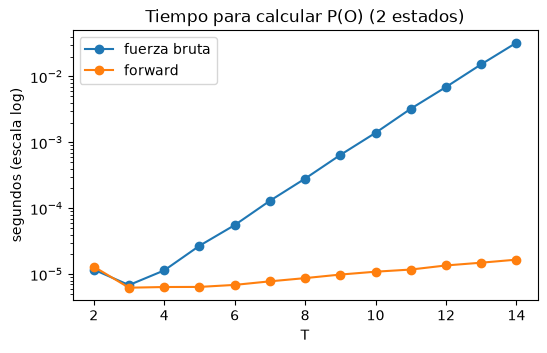

In [10]:
tiempos = []
for T in range(2, 15):
    o = list(rng.choice(3, size=T))
    t0 = time.perf_counter(); verosimilitud_fuerza_bruta(o, pi, A, B); t_bruta = time.perf_counter() - t0
    t0 = time.perf_counter(); forward(o, pi, A, B); t_fwd = time.perf_counter() - t0
    tiempos.append((T, t_bruta, t_fwd))

tiempos = pd.DataFrame(tiempos, columns=["T", "fuerza bruta", "forward"]).set_index("T")
tiempos.plot(logy=True, marker="o", figsize=(6, 3.5), title="Tiempo para calcular P(O) (2 estados)")
plt.ylabel("segundos (escala log)")
plt.show()

La fuerza bruta crece exponencialmente (una recta en escala logarítmica) mientras que forward crece linealmente con $T$.

**Para qué sirve $P(O)$:** comparar modelos (¿qué HMM explica mejor estos datos?), clasificar secuencias (un HMM por clase, como en el reconocimiento de palabras aisladas en voz) y, combinado con el algoritmo *backward*, estimar los parámetros sin etiquetas con **Baum-Welch** (un caso del algoritmo EM).

> En la práctica los $\alpha$ se vuelven diminutos con secuencias largas (*underflow*), así que se trabaja con logaritmos (usando `logsumexp`) o se normaliza en cada paso.

<a id="aprendizaje-supervisado-un-hmm-para-etiquetado-gramatical"></a>
<h2 style="color: #007ACC;">Aprendizaje supervisado: un HMM para etiquetado gramatical</h2>

Cuando tenemos un **corpus anotado**, aprender el HMM es tan simple como contar (estimación por máxima verosimilitud):

$$\pi_i = \frac{C(\text{oraciones que empiezan con } i)}{\#\text{oraciones}}, \qquad a_{ij} = \frac{C(i \rightarrow j)}{C(i)}, \qquad b_j(w) = \frac{C(j, w)}{C(j)}$$

Usaremos **CESS-ESP**, el corpus de noticias en español del cuaderno 06, que tiene cada palabra anotada con su categoría gramatical. Simplificamos sus etiquetas detalladas al conjunto universal del cuaderno 02.

In [11]:
# --- Carga de CESS-ESP con etiquetas gramaticales simplificadas -------------------------
# Las etiquetas originales siguen el estándar EAGLES (p. ej. "ncms000" = nombre común masculino
# singular). Las reducimos a categorías universales usando su primera letra.
MAPA_EAGLES = {"n": "NOUN", "v": "VERB", "a": "ADJ", "d": "DET", "s": "ADP", "r": "ADV", "p": "PRON",
               "c": "CONJ", "f": "PUNCT", "z": "NUM", "w": "NUM", "i": "INTJ"}


def etiqueta_universal(eagles):
    eagles = eagles.lower()
    if eagles.startswith("np"):
        return "PROPN"
    if eagles.startswith(("va", "vs")):  # haber y ser como auxiliares
        return "AUX"
    return MAPA_EAGLES.get(eagles[0], "X")


SIGNOS = {"-fpa-": "(", "-fpt-": ")", "-fe-": '"'}
corpus = [[(SIGNOS.get(w.lower(), w.lower()), etiqueta_universal(t)) for w, t in s if not w.startswith("*")]
          for s in cess_esp.tagged_sents()]

print(f"Oraciones: {len(corpus)} | Tokens: {sum(map(len, corpus)):,}")
print(corpus[0][:10])
print(Counter(t for s in corpus for _, t in s).most_common())

Oraciones: 6030 | Tokens: 188,802
[('el', 'DET'), ('grupo', 'NOUN'), ('estatal', 'ADJ'), ('electricité_de_france', 'PROPN'), ('(', 'PUNCT'), ('edf', 'PROPN'), (')', 'PUNCT'), ('anunció', 'VERB'), ('hoy', 'ADV'), (',', 'PUNCT')]
[('NOUN', 33736), ('ADP', 28695), ('DET', 27425), ('PUNCT', 24173), ('VERB', 18014), ('ADJ', 13703), ('CONJ', 10381), ('PROPN', 9993), ('PRON', 8511), ('ADV', 7270), ('AUX', 4135), ('NUM', 2722), ('INTJ', 40), ('X', 4)]


In [12]:
rng = np.random.default_rng(SEED)
orden = rng.permutation(len(corpus))
corte = int(0.9 * len(corpus))
train = [corpus[i] for i in orden[:corte]]
test = [corpus[i] for i in orden[corte:]]

ETIQUETAS = sorted({t for s in train for _, t in s})
t2i = {t: i for i, t in enumerate(ETIQUETAS)}
print(f"{len(ETIQUETAS)} etiquetas: {ETIQUETAS}")

14 etiquetas: ['ADJ', 'ADP', 'ADV', 'AUX', 'CONJ', 'DET', 'INTJ', 'NOUN', 'NUM', 'PRON', 'PROPN', 'PUNCT', 'VERB', 'X']


In [13]:
def estimar_hmm(oraciones, alpha=1e-3):
    N = len(ETIQUETAS)
    c_ini = np.zeros(N)
    c_trans = np.zeros((N, N))
    c_emis = {t: Counter() for t in ETIQUETAS}
    for s in oraciones:
        tags = [t2i[t] for _, t in s]
        c_ini[tags[0]] += 1
        for i, j in zip(tags, tags[1:]):
            c_trans[i, j] += 1
        for w, t in s:
            c_emis[t][w] += 1
    # Un suavizado aditivo pequeño evita ceros en pi y A
    pi = (c_ini + alpha) / (c_ini + alpha).sum()
    A = (c_trans + alpha) / (c_trans + alpha).sum(axis=1, keepdims=True)
    return pi, A, c_emis


pi_pos, A_pos, c_emis = estimar_hmm(train)
pd.Series(pi_pos, index=ETIQUETAS).sort_values(ascending=False).head(6).round(3).to_frame("π (inicio de oración)")

,π (inicio de oración)
DET,0.318
ADP,0.151
ADV,0.109
PROPN,0.098
PUNCT,0.087
CONJ,0.082


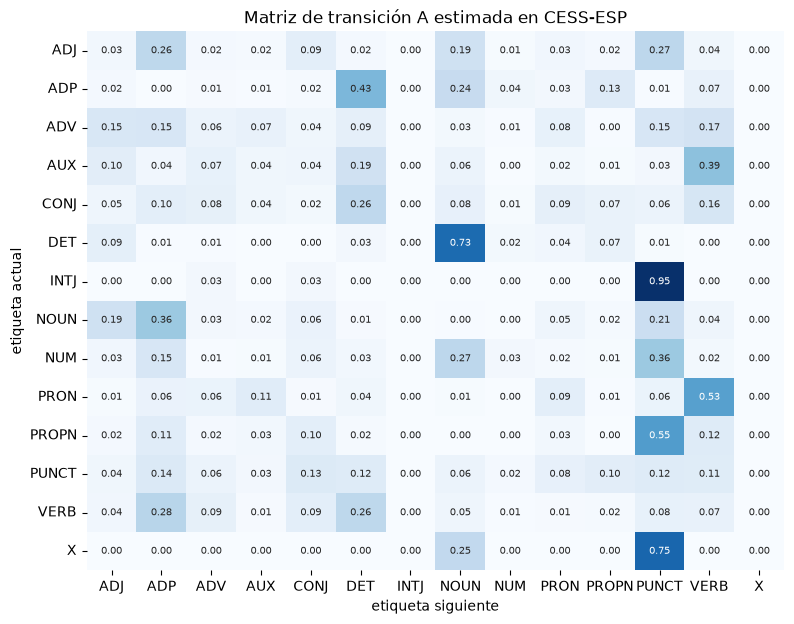

In [14]:
plt.figure(figsize=(9, 7))
sns.heatmap(A_pos, annot=True, fmt=".2f", cmap="Blues", xticklabels=ETIQUETAS, yticklabels=ETIQUETAS,
            annot_kws={"size": 7}, cbar=False)
plt.xlabel("etiqueta siguiente")
plt.ylabel("etiqueta actual")
plt.title("Matriz de transición A estimada en CESS-ESP")
plt.show()

La matriz de transición **resume la gramática del español** sin que nadie la haya programado:

- Después de un determinante (`DET`) viene un sustantivo (`NOUN`) en casi tres de cada cuatro casos.
- Después de una preposición (`ADP`) lo más común es un determinante (*de la casa*), seguido de sustantivos y nombres propios (*en Madrid*).
- Después de un sustantivo es frecuente una preposición (*presidente de...*), un signo de puntuación o un adjetivo. En conteos absolutos, la secuencia sustantivo + adjetivo es más del doble de frecuente que adjetivo + sustantivo: en español el adjetivo suele ir **después** del sustantivo (*la casa blanca*), al revés que en inglés (*the white house*).
- Después de un auxiliar (`AUX`) lo más probable es un verbo (*ha dicho*, *fue elegido*).

La matriz de emisión $B$ dice qué palabras produce cada etiqueta:

In [15]:
pd.DataFrame({
    t: [f"{w} ({c / sum(c_emis[t].values()):.2f})" for w, c in c_emis[t].most_common(5)]
    for t in ["DET", "NOUN", "VERB", "AUX", "ADJ", "ADP", "PROPN"]
}).T

,0,1,2,3,4
DET,la (0.25),el (0.22),los (0.11),un (0.07),las (0.07)
NOUN,años (0.01),presidente (0.01),millones (0.01),país (0.01),año (0.00)
VERB,está (0.01),dijo (0.01),tiene (0.01),puede (0.01),hace (0.01)
AUX,es (0.24),ha (0.17),han (0.07),fue (0.06),son (0.06)
ADJ,primer (0.01),primera (0.01),pasado (0.01),mayor (0.01),gran (0.01)
ADP,de (0.36),en (0.16),a (0.10),del (0.08),con (0.05)
PROPN,gobierno (0.02),españa (0.01),madrid (0.01),barcelona (0.01),pp (0.01)


Las palabras ambiguas aparecen en varias filas de $B$. Por ejemplo, *la* es determinante (*la casa*) o pronombre (*la vi*), y *que* puede ser pronombre relativo o conjunción. El HMM resolverá estas ambigüedades combinando $B$ con las transiciones $A$:

In [16]:
for palabra in ["la", "que", "como", "bajo", "sobre"]:
    dist = {t: c_emis[t][palabra] for t in ETIQUETAS if c_emis[t][palabra] > 0}
    total = sum(dist.values())
    print(f"{palabra:<6}", ", ".join(f"{t}: {c / total:.2f}" for t, c in sorted(dist.items(), key=lambda x: -x[1])))

la     DET: 0.99, PRON: 0.01, PROPN: 0.00
que    PRON: 0.54, CONJ: 0.46
como   CONJ: 0.93, ADP: 0.07, PRON: 0.00
bajo   ADP: 0.88, ADJ: 0.10, NOUN: 0.02
sobre  ADP: 1.00, NOUN: 0.00


<a id="el-hmm-como-modelo-generativo"></a>
<h2 style="color: #007ACC;">El HMM como modelo generativo</h2>

Como cualquier modelo generativo, nuestro HMM puede **inventar oraciones**: primero genera una secuencia de etiquetas con $A$ y luego cada palabra con $B$. Las oraciones respetan la estructura gramatical (el orden de las categorías), pero no tienen sentido, porque cada palabra se elige sin mirar a las demás:

In [17]:
def generar_oracion(rng, max_len=15):
    palabras = []
    q = rng.choice(len(ETIQUETAS), p=pi_pos)
    for _ in range(max_len):
        emis = c_emis[ETIQUETAS[q]]
        vocab_q, conteos = zip(*emis.items())
        palabra = vocab_q[rng.choice(len(vocab_q), p=np.array(conteos) / sum(conteos))]
        palabras.append(f"{palabra}/{ETIQUETAS[q]}")
        if palabra == ".":
            break
        q = rng.choice(len(ETIQUETAS), p=A_pos[q])
    return " ".join(palabras)


rng = np.random.default_rng(SEED)
for _ in range(4):
    print(generar_oracion(rng), "\n")

detroit/PROPN ./PUNCT 

en_base_a/ADP 18_de_septiembre/NUM de/ADP otros/DET poesía/NOUN en/ADP piel/NOUN ./PUNCT 

venezuela/PROPN ayudarles/VERB palabra/NOUN a/ADP los/DET voceros/NOUN de/ADP la/DET el/DET educación/NOUN con/ADP oro/NOUN "/PUNCT la/DET trabajo/NOUN 



lejano/ADJ eso/PRON dado/VERB la/DET los/DET semanas/NOUN ./PUNCT 



**Resumen:**

- Un HMM combina una cadena de Markov sobre **estados ocultos** (las etiquetas) con una distribución de **emisión** de las observaciones (las palabras).
- El algoritmo **forward** calcula la verosimilitud $P(O)$ en tiempo $O(N^2T)$ gracias a la programación dinámica.
- Con datos anotados, los parámetros se estiman **contando**.

En el siguiente cuaderno resolveremos el problema más útil para el etiquetado: encontrar la **secuencia de etiquetas más probable** para una oración nueva, con el **algoritmo de Viterbi**. Para eso también tendremos que decidir qué hacer con las palabras que no aparecen en $B$.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Bird, S., Klein, E. & Loper, E. (2009). *Natural Language Processing with Python*. O'Reilly Media. [nltk.org/book](https://www.nltk.org/book/)
- Rabiner, L. R. (1989). A Tutorial on Hidden Markov Models and Selected Applications in Speech Recognition. *Proceedings of the IEEE*, 77(2).
- Eisner, J. (2002). An Interactive Spreadsheet for Teaching the Forward-Backward Algorithm. *ACL Workshop on Effective Tools and Methodologies for Teaching NLP*.